# Deep Learning, Phase 1, Day 2: Loss, Backpropagation and Training from Scratch


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
sns.set_theme(style='whitegrid')
np.random.seed(42)

## 1. Loss functions
The **loss** is one number that says how wrong the predictions are. Training means making it small.

| Loss | Formula (average over samples) | Used for |
|---|---|---|
| **MSE** (mean squared error) | mean of (y - y_hat)^2 | regression |
| **Binary cross-entropy** | -mean of [ y log(p) + (1 - y) log(1 - p) ] | two classes, p = predicted probability |
| **Categorical cross-entropy** | -mean of log(probability given to the true class) | more than two classes (softmax output) |

Cross-entropy punishes **confident wrong answers** very strongly. See it:

good predictions     BCE = 0.164   MSE = 0.025
unsure (all 0.5)     BCE = 0.693   MSE = 0.250
confidently WRONG    BCE = 1.956   MSE = 0.725


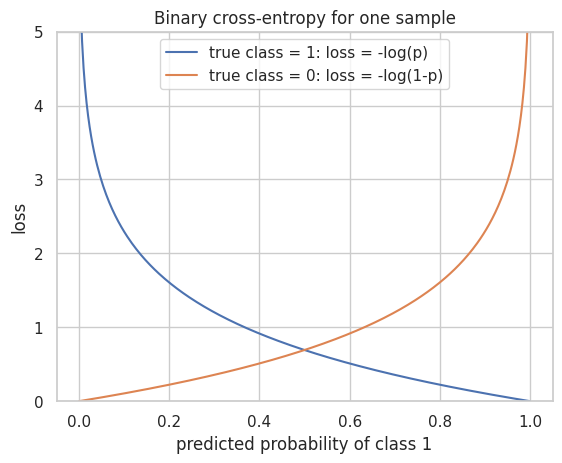

In [2]:
def mse(y, y_hat): return np.mean((y - y_hat) ** 2)
def bce(y, p, eps=1e-12):
    p = np.clip(p, eps, 1 - eps)             # avoid log(0)
    return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

y_true = np.array([1, 1, 0, 0])
for name, p in {'good predictions': np.array([0.9, 0.8, 0.1, 0.2]),
                'unsure (all 0.5)': np.array([0.5, 0.5, 0.5, 0.5]),
                'confidently WRONG': np.array([0.1, 0.2, 0.9, 0.8])}.items():
    print(f'{name:20s} BCE = {bce(y_true, p):.3f}   MSE = {mse(y_true, p):.3f}')

p = np.linspace(0.001, 0.999, 300)
plt.plot(p, -np.log(p), label='true class = 1: loss = -log(p)')
plt.plot(p, -np.log(1 - p), label='true class = 0: loss = -log(1-p)')
plt.xlabel('predicted probability of class 1'); plt.ylabel('loss'); plt.ylim(0, 5); plt.legend(); plt.title('Binary cross-entropy for one sample'); plt.show()

**Write below what you see:** the loss is near 0 when the model is confident and right, and shoots up when it is confident and wrong.

## 2. Gradient descent and the learning rate
The loss depends on all the weights. The **gradient** tells us, for each weight, in which direction the loss increases. We move every weight a small step the **opposite** way:

**w = w - learning_rate x dLoss/dw**

- Too small a learning rate: training is very slow. Too large: the loss jumps around or explodes.
- One full pass over the data = one **epoch**. Here we use all samples at once (full-batch gradient descent). In PyTorch (Day 3) we will use mini-batches.

The hard part is computing `dLoss/dw` for every weight in a deep network. That is **backpropagation**.

## 3. Backpropagation = the chain rule, applied backwards
The loss is a chain of functions: **X -> Z1 -> A1 -> Z2 -> A2 -> Loss**. The chain rule lets us compute the gradient layer by layer, starting at the output and moving back.

A tiny example first: one sigmoid neuron `p = sigmoid(w*x + b)` with loss L = (p - y)^2, one sample. The chain rule gives
**dL/dw = dL/dp x dp/dz x dz/dw = 2(p - y) x p(1 - p) x x**. Check it against a numerical estimate:

In [3]:
def sigmoid(z): return 1 / (1 + np.exp(-z))
x, y, w, b = 1.5, 1.0, 0.4, -0.2

def loss_fn(w): return (sigmoid(w * x + b) - y) ** 2
p = sigmoid(w * x + b)
analytic = 2 * (p - y) * p * (1 - p) * x                       # chain rule
h = 1e-6
numeric = (loss_fn(w + h) - loss_fn(w - h)) / (2 * h)           # slope by nudging w
print('chain rule  :', analytic)
print('numerical   :', numeric)

chain rule  : -0.2892588061699808
numerical   : -0.289258806129844


### The formulas for our network
Our network is **input -> hidden (ReLU) -> output (sigmoid)**, with binary cross-entropy. For `m` samples, going backwards:

| Step | Formula | Meaning |
|---|---|---|
| Output error | `dZ2 = A2 - y` | sigmoid + cross-entropy simplify to prediction minus truth |
| Output weights | `dW2 = A1.T @ dZ2 / m`, `db2 = mean(dZ2)` | |
| Push error back | `dA1 = dZ2 @ W2.T` | how much each hidden neuron contributed |
| Through ReLU | `dZ1 = dA1 * (Z1 > 0)` | ReLU passes the error only where it was active |
| Hidden weights | `dW1 = X.T @ dZ1 / m`, `db1 = mean(dZ1, axis=0)` | |

Shapes of each gradient are the same as the shapes of the weight they belong to. That is a good check.

## 4. A complete MLP in NumPy

In [4]:
class MLP:
    def __init__(self, n_in, n_hidden, seed=0):
        rng = np.random.RandomState(seed)
        self.W1 = rng.randn(n_in, n_hidden) * np.sqrt(2 / n_in)        # He initialisation (good for ReLU)
        self.b1 = np.zeros(n_hidden)
        self.W2 = rng.randn(n_hidden, 1) * np.sqrt(2 / n_hidden)
        self.b2 = np.zeros(1)

    def forward(self, X):
        self.X = X
        self.Z1 = X @ self.W1 + self.b1;  self.A1 = np.maximum(0, self.Z1)     # hidden: ReLU
        self.Z2 = self.A1 @ self.W2 + self.b2; self.A2 = sigmoid(self.Z2)      # output: sigmoid
        return self.A2

    def loss(self, X, y):
        return bce(y.reshape(-1, 1), self.forward(X))

    def backward(self, y):
        m = len(y); y = y.reshape(-1, 1)
        dZ2 = self.A2 - y
        self.dW2 = self.A1.T @ dZ2 / m;  self.db2 = dZ2.mean(axis=0)
        dA1 = dZ2 @ self.W2.T
        dZ1 = dA1 * (self.Z1 > 0)
        self.dW1 = self.X.T @ dZ1 / m;   self.db1 = dZ1.mean(axis=0)

    def step(self, lr):
        self.W1 -= lr * self.dW1; self.b1 -= lr * self.db1
        self.W2 -= lr * self.dW2; self.b2 -= lr * self.db2

    def fit(self, X, y, epochs=1000, lr=0.1, X_val=None, y_val=None):
        hist = {'loss': [], 'val_loss': [], 'acc': [], 'val_acc': []}
        for ep in range(epochs):
            self.forward(X); self.backward(y); self.step(lr)           # forward, backward, update
            hist['loss'].append(self.loss(X, y)); hist['acc'].append(self.accuracy(X, y))
            if X_val is not None:
                hist['val_loss'].append(self.loss(X_val, y_val)); hist['val_acc'].append(self.accuracy(X_val, y_val))
        return hist

    def predict_proba(self, X): return self.forward(X).ravel()
    def predict(self, X): return (self.predict_proba(X) > 0.5).astype(int)
    def accuracy(self, X, y): return (self.predict(X) == y).mean()

## 5. Train it
Two-moons data, split into train and test. The test set is only for the final check, never for learning.

In [5]:
X, y = make_moons(n_samples=600, noise=0.25, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

net = MLP(n_in=2, n_hidden=8, seed=0)
print(f'Before training: loss = {net.loss(X_train, y_train):.3f}, train accuracy = {net.accuracy(X_train, y_train):.3f}')
hist = net.fit(X_train, y_train, epochs=1500, lr=0.1, X_val=X_test, y_val=y_test)
print(f'After training : loss = {hist["loss"][-1]:.3f}, train accuracy = {hist["acc"][-1]:.3f}, test accuracy = {hist["val_acc"][-1]:.3f}')

Before training: loss = 1.053, train accuracy = 0.424
After training : loss = 0.287, train accuracy = 0.887, test accuracy = 0.880


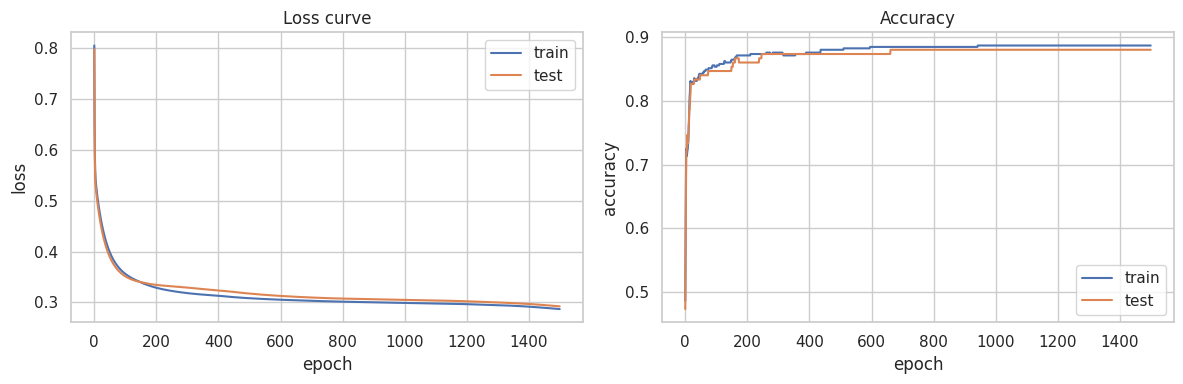

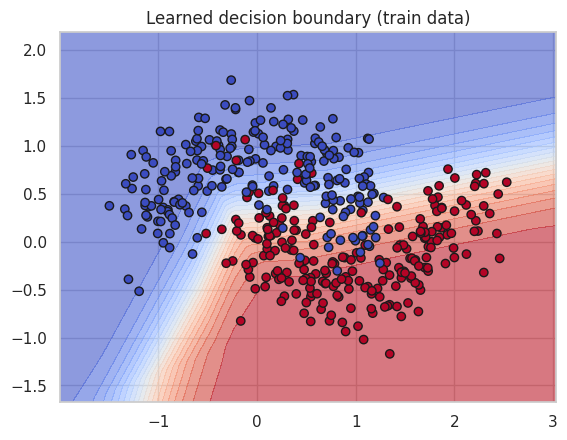

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(hist['loss'], label='train'); ax[0].plot(hist['val_loss'], label='test'); ax[0].set(xlabel='epoch', ylabel='loss', title='Loss curve'); ax[0].legend()
ax[1].plot(hist['acc'], label='train'); ax[1].plot(hist['val_acc'], label='test'); ax[1].set(xlabel='epoch', ylabel='accuracy', title='Accuracy'); ax[1].legend()
plt.tight_layout(); plt.show()

def plot_boundary(model, X, y, title, ax=None):
    ax = ax or plt.gca()
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - .5, X[:, 0].max() + .5, 250), np.linspace(X[:, 1].min() - .5, X[:, 1].max() + .5, 250))
    zz = model.predict_proba(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, zz, levels=20, cmap='coolwarm', alpha=.6); ax.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolor='k'); ax.set_title(title)
plot_boundary(net, X_train, y_train, 'Learned decision boundary (train data)'); plt.show()

## 6. Gradient check: is our backprop correct?
Backprop code is easy to get subtly wrong. The standard test: nudge a weight by a tiny `h` up and down, measure the change in loss, and compare the slope to our analytic gradient. The relative error should be tiny (below about 1e-6).

In [7]:
check = MLP(2, 5, seed=1); Xc, yc = X_train[:40], y_train[:40]
check.forward(Xc); check.backward(yc)
h, rows = 1e-5, []
for name in ['W1', 'b1', 'W2', 'b2']:
    W, dW = getattr(check, name), getattr(check, 'd' + name)
    for idx in [tuple(np.random.randint(0, s) for s in W.shape) for _ in range(3)]:
        old = W[idx]
        W[idx] = old + h; lp = check.loss(Xc, yc)
        W[idx] = old - h; lm = check.loss(Xc, yc)
        W[idx] = old
        num = (lp - lm) / (2 * h); ana = dW[idx]
        rows.append((name, idx, ana, num, abs(ana - num) / max(1e-12, abs(ana) + abs(num))))
pd.DataFrame(rows, columns=['param', 'index', 'backprop gradient', 'numerical gradient', 'relative error'])

,param,index,backprop gradient,numerical gradient,relative error
0,W1,"(0, 3)",0.000416,0.000416,1.755984e-10
1,W1,"(0, 2)",-0.000538,-0.000538,1.054529e-09
2,W1,"(1, 4)",0.038384,0.038384,1.287136e-11
3,b1,"(4,)",0.056259,0.056259,9.437010e-12
4,b1,"(1,)",-0.081323,-0.081323,1.931085e-11
5,b1,"(2,)",0.006860,0.006860,1.788848e-10
6,W2,"(2, 0)",-0.006795,-0.006795,8.929476e-11
7,W2,"(2, 0)",-0.006795,-0.006795,8.929476e-11
8,W2,"(4, 0)",0.052960,0.052960,2.352889e-11
9,b2,"(0,)",0.046152,0.046152,2.072157e-11


## 7. The learning rate matters
Same network, same starting weights, four learning rates:

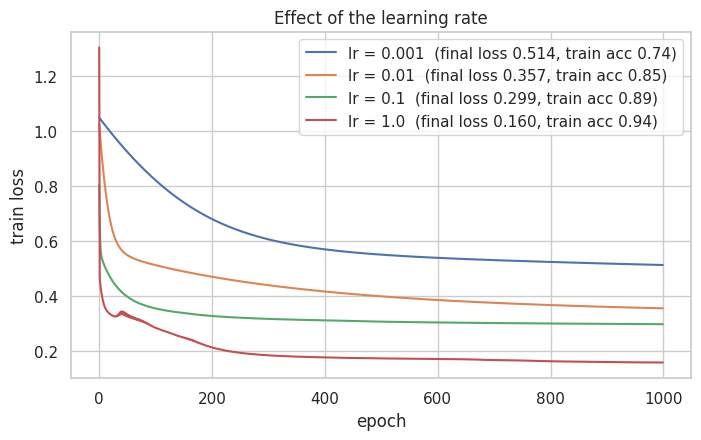

In [8]:
plt.figure(figsize=(8, 4.5))
for lr in [0.001, 0.01, 0.1, 1.0]:
    m = MLP(2, 8, seed=0); h_ = m.fit(X_train, y_train, epochs=1000, lr=lr)
    plt.plot(h_['loss'], label=f'lr = {lr}  (final loss {h_["loss"][-1]:.3f}, train acc {h_["acc"][-1]:.2f})')
plt.xlabel('epoch'); plt.ylabel('train loss'); plt.title('Effect of the learning rate'); plt.legend(); plt.show()